# 제3장. 서유기의 진짜 주인공은 누구일까? — 많이 나온 말, 숨은 주제

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ITPainter/korea-china-classics-text-mining/blob/main/notebooks/ch3_lexical.ipynb)

『서유기』에서 가장 자주 나오는 인물은 누구일까요? 이름 세기, 키워드, 숨은 주제 찾기, 문체 비교를 차례로 해 봅니다.

In [1]:
# 실습 환경 준비 (Colab에서 처음 한 번 실행)
import sys
if "google.colab" in sys.modules:
    !pip -q install "kclit @ git+https://github.com/ITPainter/korea-china-classics-text-mining.git"
from kclit.viz import setup_korean_font
print("그래프 글꼴:", setup_korean_font())

그래프 글꼴: AppleGothic


## 3.1 자주 나오는 말

2장에서 만든 호칭 사전으로 네 사람(손오공, 삼장, 저팔계, 사오정)의 몫을 셉니다.

In [2]:
from kclit import classics
xiyou = classics.xiyou()   # 처음에는 100회를 받느라 4~5분 걸립니다. 한 번 받으면 data 폴더에 저장됩니다.

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
from kclit import people
counts = people.count_names(xiyou, people.XIYOU_GROUPS)
total = counts.sum()
print(total.to_dict())
print((total / total.sum()).round(3).to_dict())

{'손오공': 7036, '삼장': 3032, '저팔계': 1873, '사오정': 975}
{'손오공': 0.545, '삼장': 0.235, '저팔계': 0.145, '사오정': 0.075}


In [4]:
lead = people.leaders(counts)
print("인물이 나오는 회:", len(lead), "회")
print(lead.value_counts().to_dict())
print("손오공 호칭이 한 번도 나오지 않는 회:", people.absent(counts, "손오공"))

인물이 나오는 회: 98 회
{'손오공': 77, '삼장': 20, '저팔계': 1}
손오공 호칭이 한 번도 나오지 않는 회: [9, 10, 11, 13, 29]


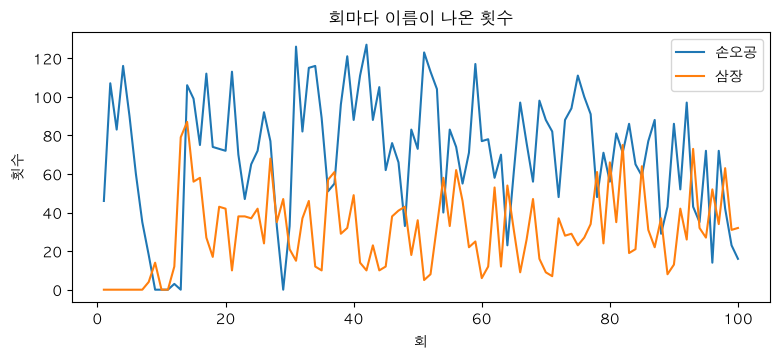

In [5]:
counts[["손오공", "삼장"]].plot(figsize=(9, 3.5), title="회마다 이름이 나온 횟수")
plt.xlabel("회"); plt.ylabel("횟수");

In [6]:
# 29회는 왜 0번일까? 27~28회에서 손오공이 삼장에게 쫓겨났습니다(28회에서 손오공이 직접 그 일을 말합니다)
import re
for m in list(re.finditer("[^。]{0,25}逐趕回來", xiyou[27]))[:1]:
    print("28회:", m.group())
print("손오공 호칭 — 28회:", counts.loc[28, "손오공"], "| 29회:", counts.loc[29, "손오공"], "| 30회:", counts.loc[30, "손오공"], "| 31회:", counts.loc[31, "손오공"])

28회: 幾番家打殺妖精；他說我行兇作惡，不要我做徒弟，把我逐趕回來
손오공 호칭 — 28회: 33 | 29회: 0 | 30회: 33 | 31회: 126


손오공이 없는 회(9, 10, 11, 13, 29회)를 직접 읽어 보세요. 숫자는 ‘여기를 읽어 보세요’라고 가리킬 뿐입니다. 29회는 27~28회에서 쫓겨난 손오공이 31회에 돌아오기 전의 회입니다.

### 키워드: 이야기 초반에 유난히 많이 나온 말

1~7회(손오공의 탄생과 소동)와 8~100회를 비교해 초반에 두드러지는 낱말을 찾습니다.

In [7]:
from kclit import freq, tokenize
tokenize.add_chinese_words(["孫行者", "孫悟空", "豬八戒", "沙和尚", "唐三藏"])
toks = [tokenize.chinese(c, min_len=2) for c in xiyou]
early = freq.frequencies(toks[:7])
rest = freq.frequencies(toks[7:])
freq.keyness(early, rest, min_count=5).head(10)

,단어,대상 빈도,참조 빈도,G2
0,猴王,97,43,360.469541
1,悟空,148,232,328.154268
2,祖師,60,7,282.256151
3,玉帝,76,93,193.272074
4,妖猴,30,3,143.386170
5,花果山,41,37,120.006559
6,真君,23,6,96.279968
7,美猴王,27,14,96.042021
8,仙女,21,4,92.720489
9,天大,44,75,92.630572


## 3.2 숨은 주제 찾기

100회를 문서 100개로 보고 LDA를 돌립니다. 어디에나 나오는 말과 너무 드문 말은 먼저 뺍니다. 토픽의 이름은 컴퓨터가 아니라 사람이 붙입니다.

In [8]:
from kclit import topics
docs = freq.filter_common(toks, min_docs=3, max_ratio=0.4)
topic_words, weights = topics.lda(docs, n_topics=5, top_words=8, seed=0)
topic_words

,토픽0,토픽1,토픽2,토픽3,토픽4
0,玉帝,娘娘,太子,國王,猴王
1,陛下,大仙,老者,公主,老者
2,王道,道士,光蕊,女子,袈裟
3,天王,太宗,寶貝,袈裟,太子
4,國王,老者,妖道,老道,魔王
5,公主,包袱,老魔道,御弟,如來
6,菩薩道,王道,婆婆,道士,祖師
7,太宗,寶貝,圈子,四眾,王子


In [9]:
weights.index = range(1, len(weights) + 1)
dominant = weights.idxmax(axis=1)
print("회차 묶음별로 가장 강한 토픽:")
print(dominant.groupby((dominant.index - 1) // 20 * 20 + 1).agg(lambda s: s.value_counts().to_dict()))

회차 묶음별로 가장 강한 토픽:
1     {'토픽4': 9, '토픽0': 6, '토픽1': 2, '토픽3': 2, '토픽2'...
21    {'토픽4': 7, '토픽0': 4, '토픽1': 4, '토픽3': 3, '토픽2'...
41    {'토픽1': 5, '토픽2': 5, '토픽0': 4, '토픽4': 3, '토픽3'...
61    {'토픽4': 7, '토픽3': 5, '토픽2': 3, '토픽1': 3, '토픽0'...
81             {'토픽4': 8, '토픽3': 5, '토픽0': 4, '토픽1': 3}
dtype: object


In [10]:
# 토픽을 3개로 줄이면 어떨까? 그리고 대표 회차는?
t3, w3 = topics.lda(docs, n_topics=3, top_words=10, seed=0)
w3.index = range(1, len(w3) + 1)
display(t3)
print("가장 강한 토픽별 회 수:", w3.idxmax(axis=1).value_counts().sort_index().to_dict())
print("34회:", w3.loc[34].round(2).to_dict())
print("11회:", w3.loc[11].round(2).to_dict())

,토픽0,토픽1,토픽2
0,國王,如來,老者
1,公主,女子,妖道
2,玉帝,太宗,寶貝
3,王道,娘娘,袈裟
4,天王,太子,老妖
5,陛下,唐王,太子
6,菩薩道,道士,老怪
7,猴王,大仙,道人
8,大仙,皇帝,王子
9,哪吒,御弟,揭諦


가장 강한 토픽별 회 수: {'토픽0': 26, '토픽1': 41, '토픽2': 33}
34회: {'토픽0': 0.0, '토픽1': 0.21, '토픽2': 0.79}
11회: {'토픽0': 0.66, '토픽1': 0.34, '토픽2': 0.0}


In [11]:
# 시드를 바꿔 다섯 번 돌리면 토픽의 단어가 얼마나 달라질까?
from collections import Counter
base = [set(t3[c]) for c in t3.columns]
appear = Counter()
for seed in range(5):
    tk, _ = topics.lda(docs, n_topics=3, top_words=10, seed=seed)
    sets = [set(tk[c]) for c in tk.columns]
    appear.update(set().union(*sets))
    if seed:
        print("시드", seed, "상위 10개 단어 겹침(자카드):", [round(max(len(b & x) / len(b | x) for x in sets), 2) for b in base])
print("다섯 번 모두 상위에 오른 단어:", sorted(w for w, n in appear.items() if n == 5))

시드 1 상위 10개 단어 겹침(자카드): [0.33, 0.25, 0.25]


시드 2 상위 10개 단어 겹침(자카드): [0.33, 0.33, 0.18]


시드 3 상위 10개 단어 겹침(자카드): [0.33, 0.33, 0.25]


시드 4 상위 10개 단어 겹침(자카드): [0.25, 0.33, 0.18]
다섯 번 모두 상위에 오른 단어: ['公主', '唐王', '國王', '大仙', '天王', '太子', '太宗', '女子', '如來', '娘娘', '寶貝', '猴王', '玉帝', '王道', '老者', '袈裟', '道士', '陛下']


토픽 수를 3, 5, 8로 바꿔 가며 단어 묶음이 어떻게 달라지는지 비교해 보세요. 이름이 잘 붙지 않는다면 토픽 수를 다시 조정하라는 신호입니다. 시드를 바꾸면 단어 묶음이 꽤 달라지니, 다섯 번 모두 나온 단어만 믿고 나머지는 ‘읽어 볼 후보’로 다루세요.

## 3.3 작가의 말버릇

‘的’, ‘了’, ‘也’ 같은 기능어의 쓰임이 평균과 가장 다른 회를 찾습니다. 숫자가 클수록 문체가 평균 회차에서 멉니다.

In [12]:
from kclit import stylometry
dist = stylometry.outlier_chapters(toks, n_mfw=100)
dist.head(5).round(2)

34    0.98
58    0.98
8     0.93
18    0.91
11    0.90
Name: Delta, dtype: float64

In [13]:
# 먼 회는 왜 먼가: 평균과 가장 크게 다른 낱말
import numpy as np
from collections import Counter
from kclit.stylometry import relative_freqs
vocab = [w for w, _ in Counter(x for t in toks for x in t).most_common(100)]
matrix = np.vstack([relative_freqs(t, vocab) for t in toks])
std = matrix.std(axis=0); std[std == 0] = 1
z = (matrix - matrix.mean(axis=0)) / std
for ch in dist.index[:5]:
    row = pd.Series(z[ch - 1], index=vocab)
    print(f"{ch}회:", [(w, round(float(row[w]), 1)) for w in row.abs().sort_values(ascending=False).head(4).index])

34회: [('孫行者', 6.2), ('寶貝', 4.8), ('小妖', 4.4), ('不曾', 3.6)]
58회: [('兩個', 4.9), ('模樣', 4.4), ('弟子', 4.1), ('如來', 3.6)]
8회: [('東土', 6.3), ('菩薩', 4.9), ('怪物', 4.2), ('取經', 3.3)]
18회: [('有些', 5.6), ('多少', 3.2), ('妖怪', 3.0), ('人家', 2.7)]
11회: [('陛下', 7.4), ('只見', 2.8), ('上前', 2.1), ('一座', 1.9)]


In [14]:
# 그 회의 대목을 직접 읽어 보세요
for ch, key in [(34, "換了寶貝"), (58, "形容如一"), (8, "取經人")]:
    i = xiyou[ch - 1].find(key)
    print(f"{ch}회:", xiyou[ch - 1][max(0, i - 25): i + 30].replace("\n", " "))

34회: 不見了行者。伶俐蟲道：「哥啊，神仙也會打誑語。他說換了寶貝，度我等成仙，怎麼不辭就去了？」精細鬼道：「我們相應
58회: ：「佛法無邊。」地藏早已省悟，即對行者道：「你兩個形容如一，神通無二，若要辨明，須到雷音寺釋迦如來那裡，方得明
8회: 薩行近蓮臺，禮佛三匝道：「弟子不才，願上東土尋一個取經人來也。」諸眾擡頭觀看，那菩薩：  理圓四德，智滿金身。


문체가 다르다고 해서 작가가 다르다는 뜻은 아닙니다. 위에 나온 회는 보물 바꿔치기(34회), 진짜와 가짜 손오공을 가리는 대목(58회), 경을 구할 사람을 찾는 대목(8회)처럼 소재와 장면이 다른 회입니다.